# AC Performance and Mould risk (Combined Findings)

**BQ2:** How can seasonal weather changes, air-con performance and humidity levels be analysed to detect zones that are at risk of air-con degradation or mould growth?

This notebook joins the mould results (`bq2_humidity.ipynb`) with the AC results (`bq2_ac.ipynb`) and makes four of the five presentation charts:

| Section | Output | Slide |
|---|---|---|
| 1 | `weather_vs_ac_and_mould.png` | 1. Seasonal impact on AC energy and humidity |
| — | *(made in `bq2_humidity.ipynb`)* | 2. High humidity exposure and its reasons |
| 2 | `wet_zones_ac_on_off.png` | 3. Humidity with the AC on vs off |
| 3 | `ac_drying_2018_vs_2019.png` | 4. AC dehumidification, 2018 vs 2019 |
| 4 | `risk_matrix.png`, `combined_zone_matrix.csv` | 5. Maintenance priority by zone |

**Run order:** `bq2_humidity.ipynb` and `bq2_ac.ipynb` first; this notebook reads their saved tables.

## Summary

1. **Weather drives both AC load and humidity risk.** The AC uses about 23% more energy in the hot season than the cool season, and surfaces are at high humidity 33-37 hours a week in the hot and rainy seasons against about 6 in the cool season.
2. **Wetter air has two causes.** F5-Z5, F7-Z2 and F5-Z4 stay humid *while the AC runs* (AC not drying enough); F7-Z4, F7-Z5 and F7-Z1 are humid only when the AC is off (likely air leaks).
3. **F7-Z2 shows the clearest sign of AC degradation:** from 2018 to 2019 it went from drier than normal to much more humid at the same AC power. F5-Z4 needed 38% more power to stay only slightly drier.
4. **Four zones are high priority** (mould risk plus an AC problem): F7-Z2, F5-Z4, F5-Z5 and F3-Z4. Four more have mould risk caused by the building, not the AC.

These are inspection priorities from room sensors, not confirmed faults or confirmed mould.

## Load and calculate

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project root = the folder holding data-cleaning/; this BQ2 folder sits in analytics/ inside it
here = Path.cwd().resolve()
repo_root = next(p for p in (here, *here.parents) if (p / "data-cleaning").is_dir())
analysis_dir = repo_root / "analytics/mould-ac-degradation"
sys.path.insert(0, str(analysis_dir / "src"))
get_ipython().run_line_magic("run", f'-i "{analysis_dir / "bq2_utils.ipynb"}"')
sys.path.insert(0, str(repo_root / BASELINE_CODE_DIR))
from humidity_risk_baseline import load_bangkok_era5_weather

weather = load_bangkok_era5_weather(repo_root / WEATHER_CSV)
all_hours = merge_weather(load_zone_hourly(repo_root / ZONE_HOURLY_CSV), weather)
all_hours["zone_id"] = "F" + all_hours["floor"].astype(str) + "-Z" + all_hours["zone"].astype(str)
df = all_hours[all_hours["temp_C"].notna() & all_hours["rh_pct"].notna()].copy()
mould = pd.read_csv(analysis_dir / "outputs/bq2-humidity/zone_mould_metrics.csv").set_index("zone_id")
track_b = pd.read_csv(analysis_dir / "outputs/bq2-zone-screen/inspection_shortlist.csv").set_index("zone_id")
OUT_DIR = analysis_dir / "outputs/bq2-risk-matrix"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Track A definitions
WINDOWS = [("2018-07-01", "2018-09-30 23:00"), ("2019-03-07", "2019-10-21 23:00")]
in_window = np.any([df["Date"].between(a, b) for a, b in WINDOWS], axis=0)
suspect = set(mould.index[mould["suspect_sensor"]])
df["temp_diff"] = df["temp_C"] - df.groupby("Date")["temp_C"].transform("median")         # vs typical zone
df["moist_diff"] = df["indoor_w_gkg"] - df.groupby("Date")["indoor_w_gkg"].transform("median")
df["ac_on"] = df["ac_kW"] > 0.5
on = df[in_window & df["ac_on"]]
off = df[in_window & ~df["ac_on"] & df["hour"].between(1, 5)]                              # AC off at night

# Why each zone is damp (Track A rule) and whether the AC is involved
avg = df[in_window].groupby("zone_id")[["temp_diff", "moist_diff"]].mean()
wetter, colder = avg["moist_diff"] > 0.2, avg["temp_diff"] < -0.2
zones = pd.DataFrame({"wetter_AC_on": on.groupby("zone_id")["moist_diff"].mean(),
                      "wetter_AC_off": off.groupby("zone_id")["moist_diff"].mean(),
                      "colder_AC_on": -on.groupby("zone_id")["temp_diff"].mean(),
                      "colder_AC_off": -off.groupby("zone_id")["temp_diff"].mean()}).round(1) + 0.0
zones["not_drying"] = wetter & (zones["wetter_AC_on"] > 0.5)
zones["air_leaks"] = wetter & ~zones["not_drying"] & (zones["wetter_AC_off"] > 0.5)
zones["overcooling"] = colder & (zones["colder_AC_on"] > zones["colder_AC_off"] + 0.5)

# Same months in both years (Track B's July-August), working days, AC running
ja = df[df["Date"].dt.month.isin([7, 8]) & (df["day_type"] == "working day") & df["ac_on"]]
yr = ja.groupby(["zone_id", "year"]).agg(extra=("moist_diff", "mean"), kw=("ac_kW", "mean")).unstack()

INK = "#52514e"                                                                            # text colour
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})

## 1. Seasonal impact on AC energy and humidity (slide 1)

Average Daily AC Energy Consumption on Working Days | days used: {'Hot': 59, 'Rainy': 182, 'Cool': 120}
Average Weekly Hours at High Humidity Levels | days used: {'Hot': 55, 'Rainy': 102, 'Cool': 39}


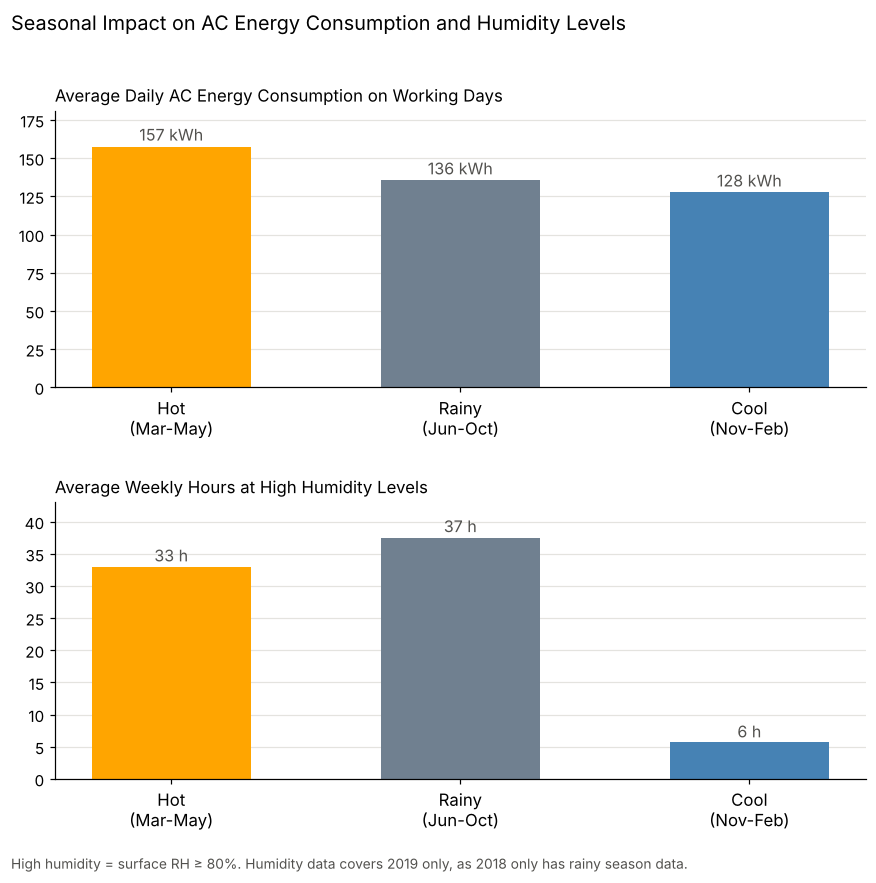

In [2]:
SEASONS = {"Hot\n(Mar-May)": [3, 4, 5], "Rainy\n(Jun-Oct)": [6, 7, 8, 9, 10], "Cool\n(Nov-Feb)": [11, 12, 1, 2]}
SEASON_COLORS = ["orange", "slategray", "steelblue"]          # Hot, Rainy, Cool
season_of = {mth: name for name, months in SEASONS.items() for mth in months}

day = all_hours[(all_hours["day_type"] == "working day") & ~all_hours["zone_id"].isin(suspect)].copy()
day["day"] = day["Date"].dt.normalize()
valid = day["temp_C"].notna() & day["rh_pct"].notna()
day["damp"] = (surface_rh_pct(day["indoor_dew_C"], day["temp_C"] - 2) >= 80).astype(float).where(valid)
per_zone = day.groupby(["zone_id", "day"]).agg(
    ac_kwh=("ac_kW", lambda s: s.sum() if s.notna().sum() == 24 else np.nan),        # complete days only
    damp_h=("damp", lambda s: s.mean() * 168 if s.notna().sum() >= 20 else np.nan))
daily = per_zone.groupby("day").mean()
daily["season"] = pd.Categorical(daily.index.month.map(season_of), categories=list(SEASONS))
daily.loc[daily.index.year == 2018, "damp_h"] = np.nan                               # damp: 2019 only

panels = [("ac_kwh", "kWh", "Average Daily AC Energy Consumption on Working Days"),
          ("damp_h", "h", "Average Weekly Hours at High Humidity Levels")]
fig, axes = plt.subplots(2, 1, figsize=(8, 8))
for ax, (col, unit, title) in zip(axes, panels):
    g = daily.dropna(subset=[col]).groupby("season", observed=False)[col].agg(["mean", "size"])
    ax.bar(range(3), g["mean"], color=SEASON_COLORS, width=0.55)
    for i, v in enumerate(g["mean"]):
        ax.text(i, v * 1.01, f"{v:.0f} {unit}", ha="center", va="bottom", fontsize=10.5, color=INK)
    ax.set_xticks(range(3), g.index)
    ax.tick_params(axis="x", labelsize=11)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(0, g["mean"].max() * 1.15)
    ax.grid(axis="x", visible=False)
    print(title, "| days used:", {name.split("\n")[0]: n for name, n in g["size"].items()})
fig.suptitle("Seasonal Impact on AC Energy Consumption and Humidity Levels", x=0.01, ha="left", fontsize=13)
fig.text(0.01, 0.005, "High humidity = surface RH ≥ 80%. "
         "Humidity data covers 2019 only, as 2018 only has rainy season data.", fontsize=9, color=INK)
fig.tight_layout(rect=(0, 0.03, 1, 0.96), h_pad=2.5)
fig.savefig(OUT_DIR / "weather_vs_ac_and_mould.png", bbox_inches="tight")
plt.show()

**What this shows:**

- **AC energy follows the heat:** highest in the hot season (about 157 kWh per zone per working day), about 23% more than the cool season (about 128 kWh).
- **High humidity follows outdoor moisture:** 33-37 hours a week in the hot and rainy seasons, about 6 in the cool season.
- **Why the later charts compare zones at the same hour:** weather moves both measures a lot, so comparing zones at the same hour keeps the weather from being mistaken for an AC fault.
- Humidity uses 2019 only, because 2018 has rainy-season data only. AC energy also depends on how busy the building is, so this is the overall seasonal pattern, not a weather-only effect.

## 2. Humidity with the AC on vs off (slide 3)

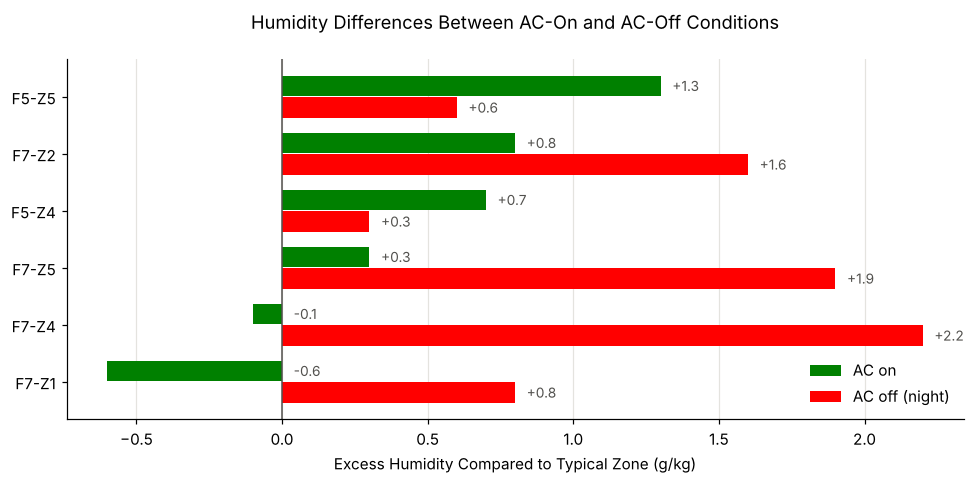

In [3]:
wet = zones[wetter].copy()
wet = wet.sort_values(["not_drying", "wetter_AC_on"], ascending=[False, False])
y = np.arange(len(wet))[::-1]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y + 0.19, wet["wetter_AC_on"], height=0.36, color="green", label="AC on")
ax.barh(y - 0.19, wet["wetter_AC_off"], height=0.36, color="red", label="AC off (night)")
for yi, a, b in zip(y, wet["wetter_AC_on"], wet["wetter_AC_off"]):
    ax.text(max(a, 0) + 0.04, yi + 0.19, f"{a:+.1f}", va="center", fontsize=9, color=INK)
    ax.text(max(b, 0) + 0.04, yi - 0.19, f"{b:+.1f}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, wet.index)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Excess Humidity Compared to Typical Zone (g/kg)")
ax.set_title("Humidity Differences Between AC-On and AC-Off Conditions", loc="center", pad=20)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "wet_zones_ac_on_off.png", bbox_inches="tight")
plt.show()

**What this shows:** **F5-Z5, F7-Z2 and F5-Z4** stay 0.7-1.3 g/kg wetter than other zones even while their AC runs, so their AC is not drying them enough. F7-Z4, F7-Z5 and F7-Z1 are normal while the AC runs and only get wet when it is off, which points to air leaks rather than the AC.

## 3. AC dehumidification, 2018 vs 2019 (slide 4)

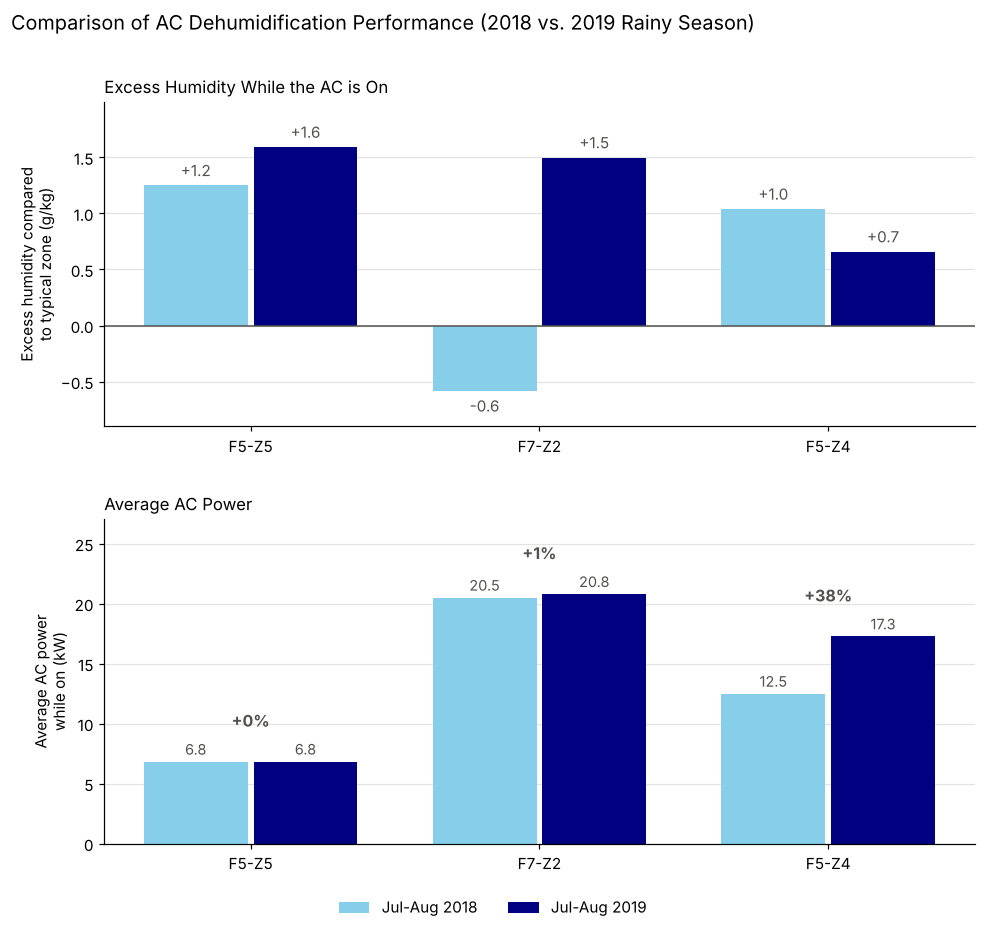

In [4]:
drying = list(wet.index[wet["not_drying"]])
x = np.arange(len(drying))
power_change = (yr["kw"][2019][drying] / yr["kw"][2018][drying] - 1) * 100

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 8.5))

# Top: excess humidity while the AC runs, 2018 vs 2019
ax.bar(x - 0.19, yr["extra"][2018][drying], width=0.36, color="skyblue", label="Jul-Aug 2018")
ax.bar(x + 0.19, yr["extra"][2019][drying], width=0.36, color="navy", label="Jul-Aug 2019")
for xi, z in zip(x, drying):
    for dx, year in [(-0.19, 2018), (0.19, 2019)]:
        v = yr["extra"][year][z]
        ax.text(xi + dx, v + (0.05 if v >= 0 else -0.05), f"{v:+.1f}", ha="center",
                va="bottom" if v >= 0 else "top", fontsize=10, color=INK)
ax.set_xticks(x, drying)
ax.axhline(0, color=INK, lw=1)
ax.set_ylim(min(-0.9, yr["extra"].loc[drying].min().min() - 0.3), yr["extra"].loc[drying].max().max() + 0.4)
ax.set_ylabel("Excess humidity compared\nto typical zone (g/kg)")
ax.set_title("Excess Humidity While the AC is On", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)

# Bottom: AC power in each year, with the % change above each pair
kw18, kw19 = yr["kw"][2018][drying], yr["kw"][2019][drying]
ax2.bar(x - 0.19, kw18, width=0.36, color="skyblue", label="Jul-Aug 2018")
ax2.bar(x + 0.19, kw19, width=0.36, color="navy", label="Jul-Aug 2019")
for xi, z in zip(x, drying):
    ax2.text(xi - 0.19, kw18[z] + 0.3, f"{kw18[z]:.1f}", ha="center", va="bottom", fontsize=9.5, color=INK)
    ax2.text(xi + 0.19, kw19[z] + 0.3, f"{kw19[z]:.1f}", ha="center", va="bottom", fontsize=9.5, color=INK)
    ax2.text(xi, max(kw18[z], kw19[z]) + 2.6, f"{power_change[z]:+.0f}%", ha="center", va="bottom",
             fontsize=10.5, fontweight="bold", color=INK)
ax2.set_xticks(x, drying)
ax2.set_ylim(0, max(kw18.max(), kw19.max()) * 1.3)
ax2.set_ylabel("Average AC power\nwhile on (kW)")
ax2.set_title("Average AC Power", loc="left", fontsize=11)
ax2.grid(axis="x", visible=False)

fig.suptitle("Comparison of AC Dehumidification Performance (2018 vs. 2019 Rainy Season)", x=0.01, ha="left", fontsize=13)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0.04, 1, 0.97), h_pad=2.5)
fig.savefig(OUT_DIR / "ac_drying_2018_vs_2019.png", bbox_inches="tight")
plt.show()

**What this shows:**

- **F7-Z2:** went from slightly drier than typical (-0.6) to **1.5 g/kg wetter**, at the **same AC power**. It is the only zone whose moisture with the AC on rose; the AC analysis (Track B) found the same.
- **F5-Z5:** wetter than typical in **both** years and slightly worse in 2019, at unchanged power: a long-standing drying shortfall.
- **F5-Z4:** slightly drier, but only with **38% more AC power**: working harder for little gain, consistent with lost efficiency (also found by Track B).

## 4. Maintenance priority by zone (slide 5)

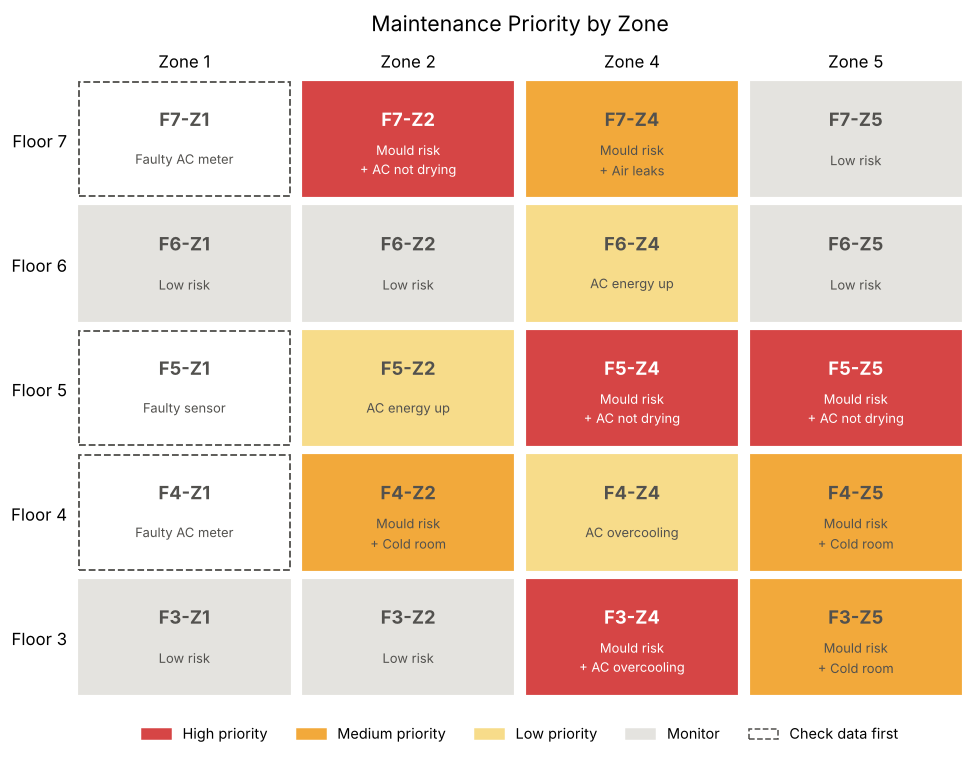

In [5]:
B_AC_LEAD = ["Inspect energy and controls", "Inspect energy change; validate reference",
             "Inspect environment; validate reference", "Review fill-dependent energy lead"]
m = mould[["mould_priority", "time_of_wetness_h"]].join(zones[["not_drying", "air_leaks", "overcooling"]])
m["trackB"] = track_b["inspection_category"]
m["ac_concern"] = m["not_drying"] | m["overcooling"] | m["trackB"].isin(B_AC_LEAD)
m["data_hold"] = m["trackB"].str.startswith("Verify") | m.index.isin(suspect)
high = m["mould_priority"] == "Inspect first"
m["action"] = np.select([m["data_hold"], high & m["ac_concern"], high, m["ac_concern"]],
                        ["4. Verify sensor or meter first", "1. Inspect AC and space together",
                         "2. Inspect area", "3. Review AC operation"], default="5. Monitor")
m["reason"] = np.select(
    [m.index.isin(suspect), m["data_hold"], m["not_drying"], m["overcooling"], m["air_leaks"],
     m["trackB"].isin(B_AC_LEAD), colder.reindex(m.index)],
    ["suspect sensor", "AC meter check", "AC not drying enough", "AC overcooling", "air leaks",
     "AC energy change", "colder room, not AC-driven"], default="typical")
m = m.sort_values(["action", "time_of_wetness_h"], ascending=[True, False])
m.to_csv(OUT_DIR / "combined_zone_matrix.csv")

from matplotlib.patches import Patch

# Colour = priority level; text in each box = the problem found in that zone
PRIORITY = {"1. Inspect AC and space together": ("High priority", "#d64545", "white", "Mould risk"),
            "2. Inspect area": ("Medium priority", "#f2a93b", INK, "Mould risk"),
            "3. Review AC operation": ("Low priority", "#f7dc8a", INK, ""),
            "5. Monitor": ("Monitor", "#e4e3df", INK, ""),
            "4. Verify sensor or meter first": ("Check data first", "white", INK, "")}
PROBLEM = {"suspect sensor": "Faulty sensor", "AC meter check": "Faulty AC meter",
           "AC not drying enough": "AC not drying", "AC overcooling": "AC overcooling",
           "air leaks": "Air leaks", "AC energy change": "AC energy up",
           "colder room, not AC-driven": "Cold room", "typical": ""}

fig, ax = plt.subplots(figsize=(9, 7))
for i, floor in enumerate([7, 6, 5, 4, 3]):
    for j, zone in enumerate([1, 2, 4, 5]):
        z = f"F{floor}-Z{zone}"
        _, face, text, mould_part = PRIORITY[m.loc[z, "action"]]
        problem = "" if m.loc[z, "action"] == "5. Monitor" else PROBLEM[m.loc[z, "reason"]]
        note = "\n+ ".join(t for t in [mould_part, problem] if t) or "Low risk"
        y = 4 - i
        ax.add_patch(plt.Rectangle((j + 0.03, y + 0.04), 0.94, 0.92, facecolor=face,
                                   edgecolor=INK if face == "white" else face,
                                   linestyle="--" if face == "white" else "-", linewidth=1.2))
        ax.text(j + 0.5, y + 0.66, z, ha="center", va="center", fontsize=12, fontweight="bold", color=text)
        ax.text(j + 0.5, y + 0.33, note, ha="center", va="center", fontsize=8.5, color=text, linespacing=1.3)
ax.set_xlim(0, 4)
ax.set_ylim(0, 5)
ax.set_xticks([0.5, 1.5, 2.5, 3.5], ["Zone 1", "Zone 2", "Zone 4", "Zone 5"])
ax.set_yticks([4.5, 3.5, 2.5, 1.5, 0.5], ["Floor 7", "Floor 6", "Floor 5", "Floor 4", "Floor 3"])
ax.xaxis.tick_top()
ax.tick_params(length=0, labelsize=11)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.legend(handles=[Patch(facecolor=f, edgecolor=INK if f == "white" else f,
                         linestyle="--" if f == "white" else "-", label=lab)
                   for lab, f, _, _ in PRIORITY.values()],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=5, frameon=False, fontsize=9.5)
ax.set_title("Maintenance Priority by Zone", fontsize=14, pad=30)
fig.tight_layout()
fig.savefig(OUT_DIR / "risk_matrix.png", bbox_inches="tight")
plt.show()

**What this shows:** each zone's colour is its priority and the text is the problem found.

- **High (red): mould risk + an AC problem.** F7-Z2, F5-Z4, F5-Z5 (AC not drying) and F3-Z4 (AC overcooling).
- **Medium (amber): mould risk caused by the building, not the AC.** F7-Z4 (air leaks) and F4-Z2, F4-Z5, F3-Z5 (cold rooms).
- **Low (yellow): AC problem only.** F6-Z4, F5-Z2 (AC energy up) and F4-Z4 (AC overcooling).
- **Check data first (dashed):** F7-Z1, F4-Z1 (faulty AC meter) and F5-Z1 (faulty sensor). **Grey:** low risk, monitor.

This answers BQ2: red zones are at risk of **both**, amber of **mould**, and yellow of **AC degradation**.

## 6. Recommendations

| Priority | Zones | Action |
|---|---|---|
| **1** | **F7-Z2, F5-Z5, F5-Z4** | Check the sensor, then inspect AC dehumidification: coil, filters, airflow, condensate drain. Check drain pans and coils for mould growth too |
| **1** | **F3-Z4** | Review setpoints and controls (overcooling); also saves energy |
| 2 | F3-Z5, F4-Z5, F7-Z4, F4-Z2 | Check sensor placement (F3-Z5) and air leaks / ventilation (F7-Z4); inspect surfaces |
| 3 | F5-Z2, F4-Z4, F6-Z4 | Review AC operation and energy use |
| 4 | F7-Z1, F5-Z1, F4-Z1 | Fix the sensor or AC meter, then re-check |

**KPIs to track monthly after each fix:** extra moisture vs the typical zone while the AC runs (target: 0 g/kg or below), and damp-surface hours per week in the priority zones.

**Limitations:**
- Room sensors only: "not drying enough" is inferred from room moisture while the AC runs, not measured at the AC coil; extra moisture from people or ventilation can look similar.
- Only two summers are compared, and the sensors were removed for a firmware update in between, so the 2019 change (especially F7-Z2's) needs a sensor check before concluding the AC has degraded.
- Surface temperatures are assumed (2 °C cooler than room air) and there are no maintenance or mould-inspection records, so these are **inspection priorities, not confirmed faults or mould**.